<a href="https://colab.research.google.com/github/bdipesh3045/Data-Science-project-AI-Class-/blob/main/Final_tensorflow.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sign Language Recognition using an MLP
A simple TensorFlow notebook for AI class. Train on the training file. Split the official test file in half: the validation half picks the best of seven settings, and the test half gives the final score.

The input is 784 grayscale pixels (28 × 28). Hidden layers learn patterns; softmax gives a probability for each letter. This dataset contains 24 static letters: J and Z are excluded.


In [1]:
%pip install -q kagglehub tensorflow scikit-learn matplotlib pandas

## 1. Import libraries

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay

keras.utils.set_random_seed(42)

## 2. Load and prepare the data
Divide pixel values by 255 to put them between 0 and 1.

**Why validation comes from the test file.** The training file was built by taking each hand photo and making many small variations of it (tiny rotations, brightness changes, blur filters). If we pick validation rows at random from the training file, almost every validation image has a near twin in training. The model just recognizes the twin, so validation shows 100% while the real accuracy is much lower (our first run: 100% validation, 79% test). The official test file does not share those twins with training, so it gives an honest check.

We split the test file in half so the final test score is never used to pick the model. The two halves may share twins with each other, so the final score can be slightly optimistic.

In [3]:
data_path = Path(kagglehub.dataset_download("datamunge/sign-language-mnist"))
train_df = pd.read_csv(next(data_path.rglob("sign_mnist_train.csv")))
test_df = pd.read_csv(next(data_path.rglob("sign_mnist_test.csv")))

# Convert the original letter labels into consecutive numbers 0 to 23.
# The original labels skip J (9), so they are not consecutive.
labels = sorted(train_df["label"].unique())
letters = [chr(65 + int(label)) for label in labels]
label_map = {label: i for i, label in enumerate(labels)}

# Train on the whole training file.
X_train = train_df.drop(columns="label").to_numpy(dtype="float32") / 255.0
y_train = train_df["label"].map(label_map).to_numpy()

# Validation comes from the test file, not the training file (see note above).
X_holdout = test_df.drop(columns="label").to_numpy(dtype="float32") / 255.0
y_holdout = test_df["label"].map(label_map).to_numpy()
X_val, X_test, y_val, y_test = train_test_split(
    X_holdout, y_holdout, test_size=0.5, random_state=42, stratify=y_holdout
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)
print("Letters:", letters)

Using Colab cache for faster access to the 'sign-language-mnist' dataset.
Training: (27455, 784)
Validation: (3586, 784)
Testing: (3586, 784)
Letters: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y']


## 3. Create the model
One small function lets us change the hidden layers, activation, and learning rate. Integer labels use sparse categorical crossentropy.

In [4]:
def build_model(hidden_layers, activation, learning_rate):
    model = keras.Sequential()
    model.add(keras.Input(shape=(784,)))

    for neurons in hidden_layers:
        model.add(keras.layers.Dense(neurons, activation=activation))

    model.add(keras.layers.Dense(len(letters), activation="softmax"))
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

build_model([512, 256, 128], "relu", 0.001).summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 24)             │         3,096 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 569,240 (2.17 MB)

 Trainable params: 569,240 (2.17 MB)

 Non-trainable params: 0 (0.00 B)

## 4. Compare model settings
Choose the model using validation accuracy only. Early stopping restores the weights with the best validation accuracy and stops after four epochs without improvement. Each run uses the same split and seed; results can still vary across hardware.

With honest validation data, the settings should now get different scores instead of several tying at 100%.

In [5]:
experiments = [
    # Name, hidden layers, activation, learning rate
    ("Baseline", [512, 256, 128], "relu", 0.001),
    ("Tanh", [512, 256, 128], "tanh", 0.001),
    ("Sigmoid", [512, 256, 128], "sigmoid", 0.001),
    ("Small", [128, 64, 32], "relu", 0.001),
    ("Large", [1024, 512, 256], "relu", 0.001),
    ("Higher learning rate", [512, 256, 128], "relu", 0.01),
    ("Lower learning rate", [512, 256, 128], "relu", 0.0001)
]

results = []
best_model = None
best_accuracy = -1

for name, hidden_layers, activation, learning_rate in experiments:
    keras.backend.clear_session()
    keras.utils.set_random_seed(42)
    print("\nTraining:", name)
    model = build_model(hidden_layers, activation, learning_rate)

    early_stop = keras.callbacks.EarlyStopping(
        monitor="val_accuracy", mode="max", patience=4,
        restore_best_weights=True
    )
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=30, batch_size=128,
        callbacks=[early_stop], verbose=2
    )

    val_loss, val_accuracy = model.evaluate(X_val, y_val, verbose=0)
    results.append({
        "Model": name,
        "Layers": str(hidden_layers),
        "Activation": activation,
        "Learning rate": learning_rate,
        "Epochs run": len(history.history["loss"]),
        "Validation accuracy": val_accuracy
    })

    if val_accuracy > best_accuracy:
        best_accuracy = val_accuracy
        best_model = model
        best_history = history
        best_name = name

results_df = pd.DataFrame(results).sort_values(
    "Validation accuracy", ascending=False
)
display(results_df)
print("Best model:", best_name)


Training: Baseline
Epoch 1/30
215/215 - 9s - 40ms/step - accuracy: 0.3392 - loss: 2.1275 - val_accuracy: 0.5254 - val_loss: 1.5676
Epoch 2/30
215/215 - 5s - 22ms/step - accuracy: 0.6324 - loss: 1.1367 - val_accuracy: 0.6378 - val_loss: 1.1749
Epoch 3/30
215/215 - 3s - 15ms/step - accuracy: 0.7696 - loss: 0.7025 - val_accuracy: 0.6631 - val_loss: 1.0650
Epoch 4/30
215/215 - 3s - 15ms/step - accuracy: 0.8623 - loss: 0.4305 - val_accuracy: 0.7019 - val_loss: 1.0384
Epoch 5/30
215/215 - 3s - 15ms/step - accuracy: 0.9139 - loss: 0.2774 - val_accuracy: 0.7103 - val_loss: 1.1244
Epoch 6/30
215/215 - 5s - 22ms/step - accuracy: 0.9485 - loss: 0.1779 - val_accuracy: 0.7158 - val_loss: 1.1311
Epoch 7/30
215/215 - 4s - 17ms/step - accuracy: 0.9772 - loss: 0.0961 - val_accuracy: 0.7680 - val_loss: 0.9588
Epoch 8/30
215/215 - 5s - 23ms/step - accuracy: 0.9788 - loss: 0.0825 - val_accuracy: 0.7646 - val_loss: 1.0367
Epoch 9/30
215/215 - 5s - 22ms/step - accuracy: 0.9957 - loss: 0.0319 - val_accuracy

,Model,Layers,Activation,Learning rate,Epochs run,Validation accuracy
1,Tanh,"[512, 256, 128]",tanh,0.0010,15,0.823759
4,Large,"[1024, 512, 256]",relu,0.0010,14,0.812047
0,Baseline,"[512, 256, 128]",relu,0.0010,20,0.809537
2,Sigmoid,"[512, 256, 128]",sigmoid,0.0010,30,0.771612
6,Lower learning rate,"[512, 256, 128]",relu,0.0001,30,0.758505
5,Higher learning rate,"[512, 256, 128]",relu,0.0100,29,0.728946
3,Small,"[128, 64, 32]",relu,0.0010,23,0.702175


Best model: Tanh


## 5. Plot the best model
A growing gap between training and validation accuracy can indicate overfitting. Curves show every epoch, including epochs after the best weights were found.

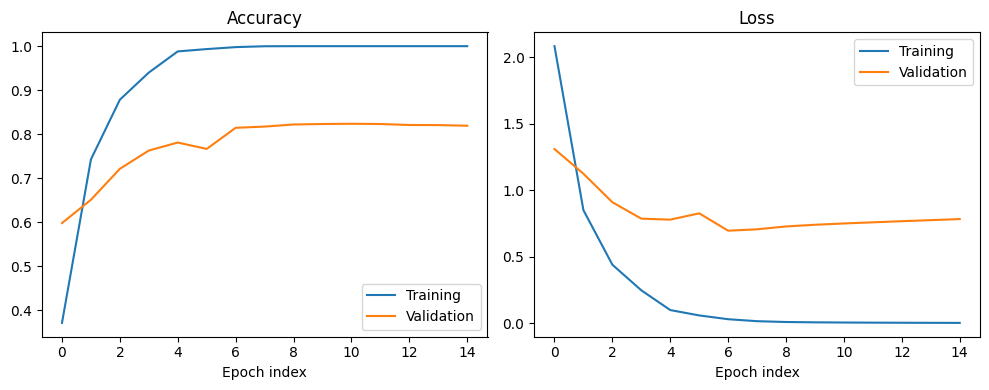

In [6]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(best_history.history["accuracy"], label="Training")
plt.plot(best_history.history["val_accuracy"], label="Validation")
plt.title("Accuracy")
plt.xlabel("Epoch index")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(best_history.history["loss"], label="Training")
plt.plot(best_history.history["val_loss"], label="Validation")
plt.title("Loss")
plt.xlabel("Epoch index")
plt.legend()

plt.tight_layout()
plt.show()

## 6. Evaluate once on the test half
Accuracy measures correct predictions overall. Macro F1 gives each letter equal importance. The confusion matrix shows which letters get confused. These test images were never used for training or for picking the model. Do not tune the model using these test results.

Best model: Tanh
Test accuracy: 82.60%
Macro F1: 0.8072


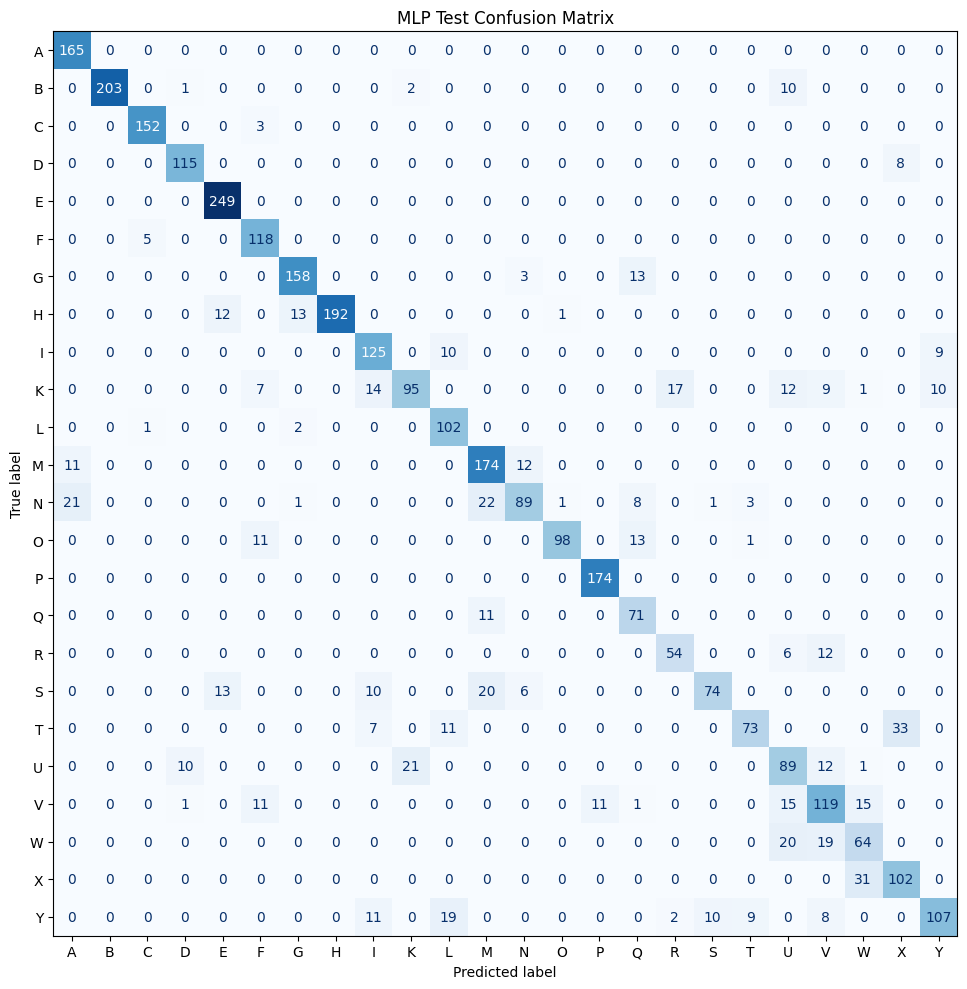

In [7]:
probabilities = best_model.predict(X_test, verbose=0)
y_pred = np.argmax(probabilities, axis=1)

print("Best model:", best_name)
print(f"Test accuracy: {accuracy_score(y_test, y_pred):.2%}")
print(f"Macro F1: {f1_score(y_test, y_pred, average='macro', zero_division=0):.4f}")

fig, ax = plt.subplots(figsize=(12, 10))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    labels=list(range(len(letters))), display_labels=letters,
    cmap="Blues", colorbar=False, ax=ax
)
plt.title("MLP Test Confusion Matrix")
plt.tight_layout()
plt.show()

## 7. Save the model and letter mapping
Prediction index 0–23 must be translated with this saved list. A demo must also apply the same grayscale, 28 × 28, flattened, and divided-by-255 preprocessing. Accuracy on this dataset does not guarantee accuracy on ordinary uploaded hand photos.

In [8]:
import json

best_model.save("best_mlp.keras")
with open("class_letters.json", "w") as file:
    json.dump(letters, file)

print("Saved best_mlp.keras and class_letters.json")

Saved best_mlp.keras and class_letters.json


### Optional: download in Google Colab
Run this cell only if you are using Colab.

In [9]:
# from google.colab import files
# files.download("best_mlp.keras")
# files.download("class_letters.json")